# AI-Generated Lineup: Mixed with reference faces

In [1]:
import os
from getpass import getpass

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

OpenAI API key:  ········


In [9]:
from pathlib import Path
from uuid import uuid4
import random
import sys
from PIL import Image as PILImage
from IPython.display import Image as DisplayImage, display
from pyWitnessAI import FaceGenerator, LineupBuilder, RawDescriptionParser, image_paths

DESCRIPTION = (
    "A man in his twenties, short hair, no beard, slim build, with prominent eyebrows and eyes"
)
REFERENCE_DIR = Path(r"D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White")

## Get 6 random faces from reference faces pool

In [12]:
pool = [
    path for path in image_paths(REFERENCE_DIR)
    if path.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
]

references = random.Random(42).sample(pool, 6)

generators = [
    FaceGenerator(
        generator_backend="openai",
        description=DESCRIPTION,
        # parser=RawDescriptionParser(lowercase=False),
        parser="raw",
        quality="high",
        reference_image=reference,
        n=1,
        output_dir="D:/PhD/Studies/FaceGenerate/Below Average/White/newStudy_V1_test/",
        write_manifest=True,
    )
    for reference in references
]
for i, reference in enumerate(references, 1):
    print(f"{i}. {reference}")
print("\nModel：", generators[0].model)
print("\nCommon prompt：\n" + generators[0].generation_prompts()[0])

1. D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\10.png
2. D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\1.png
3. D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\4.png
4. D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\9.png
5. D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\6.png
6. D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\5.png

Model： gpt-image-2.5-sunburst

Common prompt：
Make a photo of a man based on this image, with the following features: a man in his twenties, short hair, no beard, slim build, with prominent eyebrows and eyes. Make it an image portrait, only from shoulders above. Make the background gray. The people should be looking at the camera with frontal face. Do not emphasize or depict body actions, hand placement, or clothing interactions.


## Generate fillers

Generate filler 1/6，reference image：D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\10.png


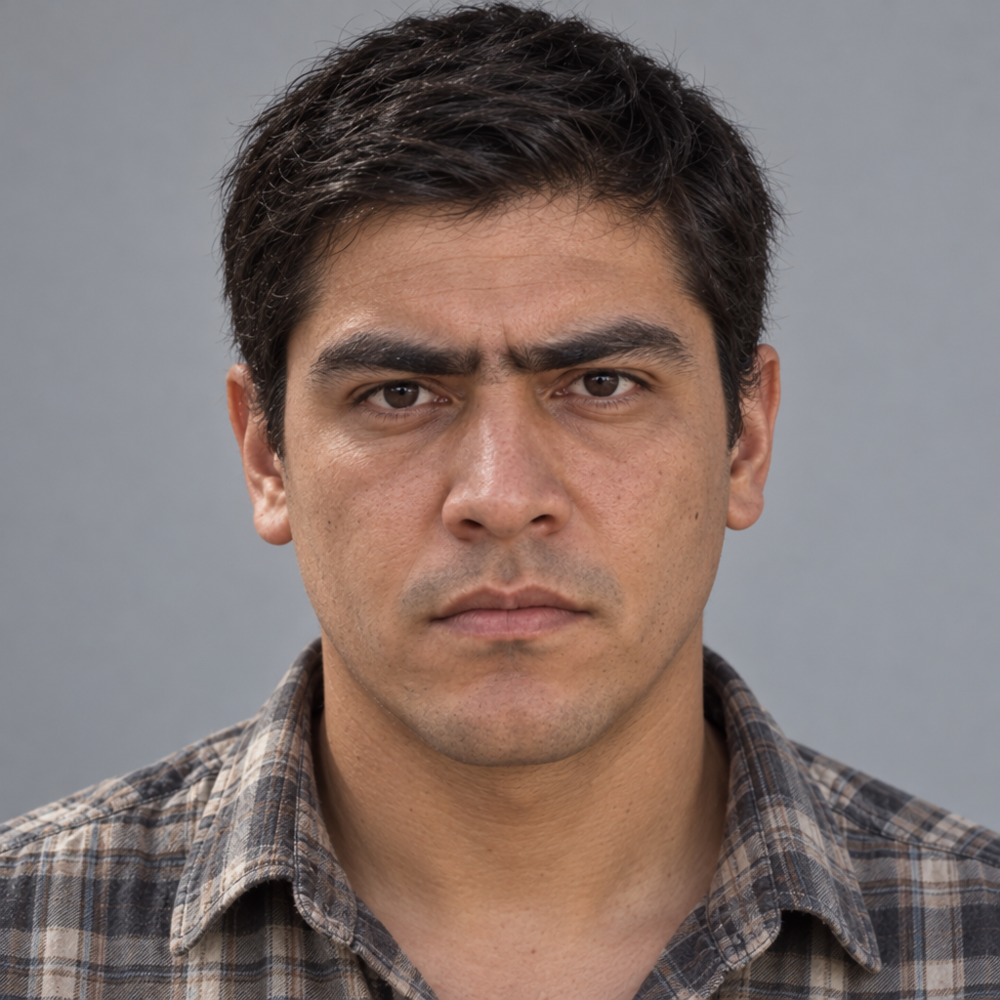

Generate filler 2/6，reference image：D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\1.png


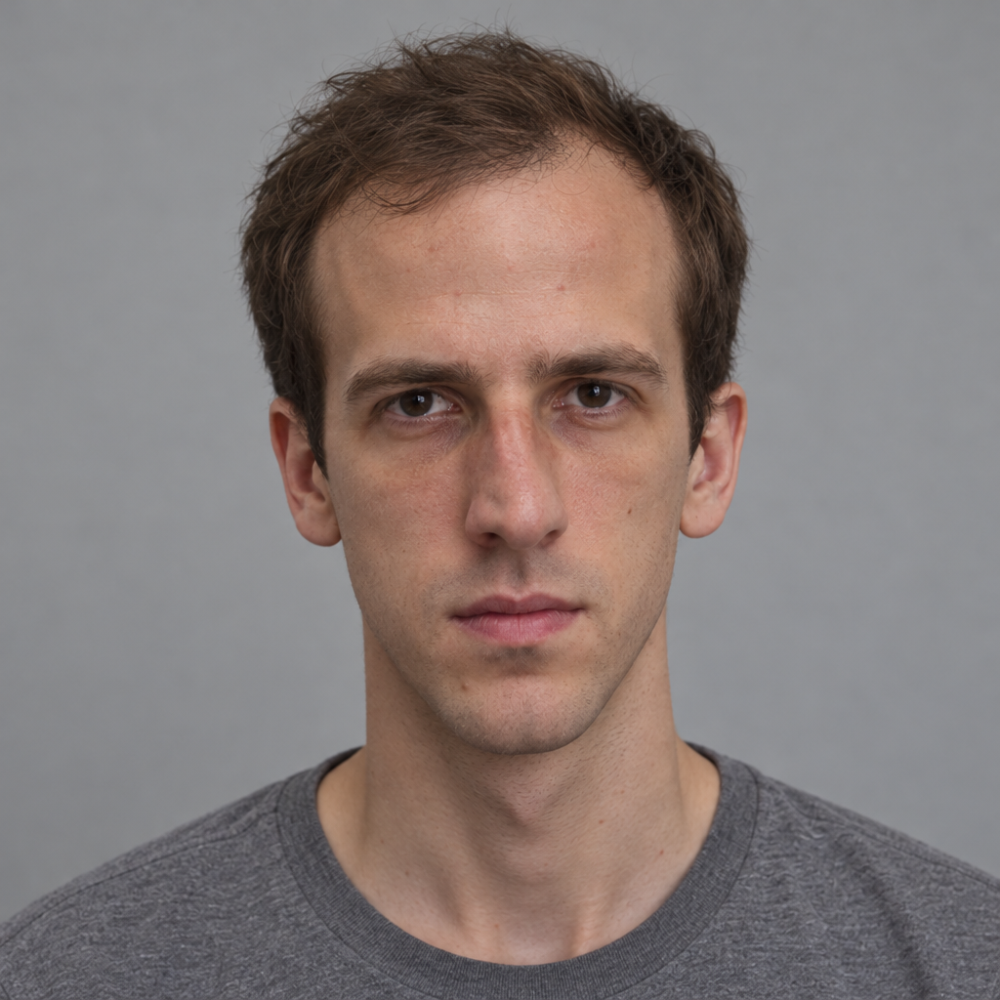

Generate filler 3/6，reference image：D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\4.png


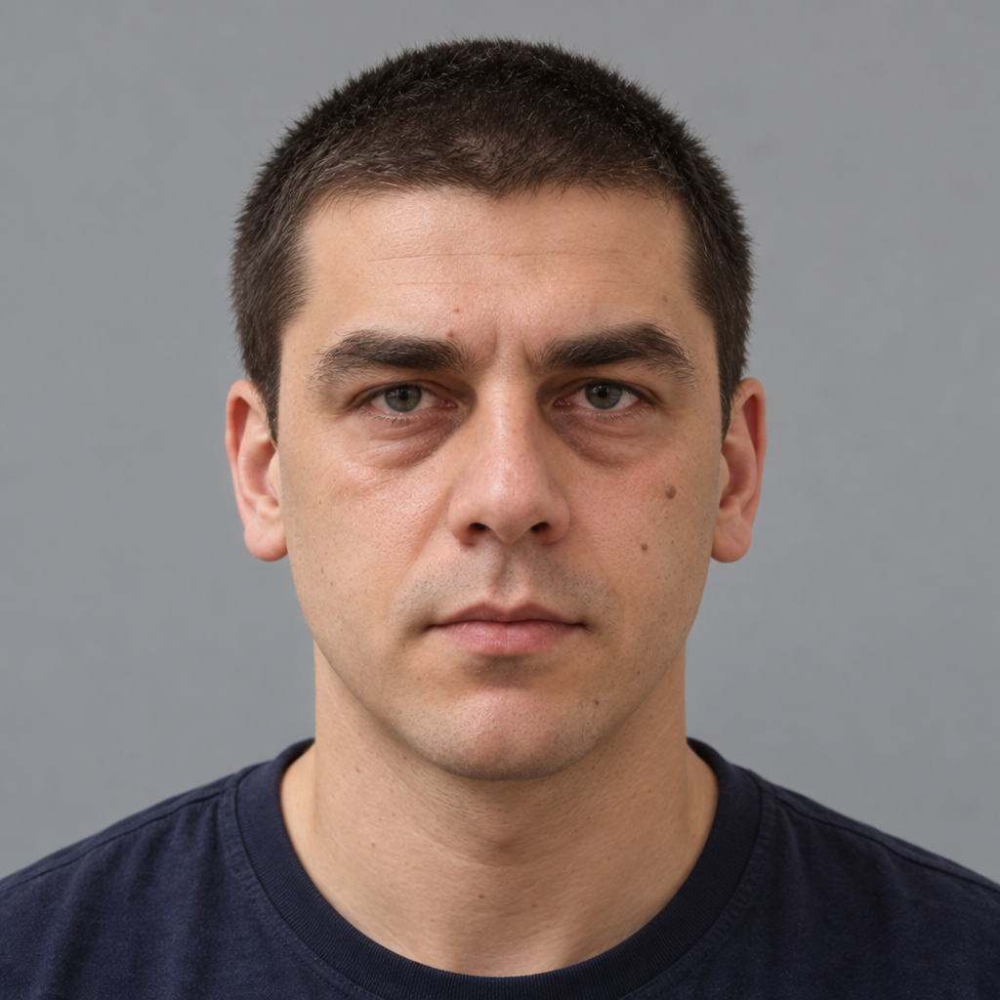

Generate filler 4/6，reference image：D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\9.png


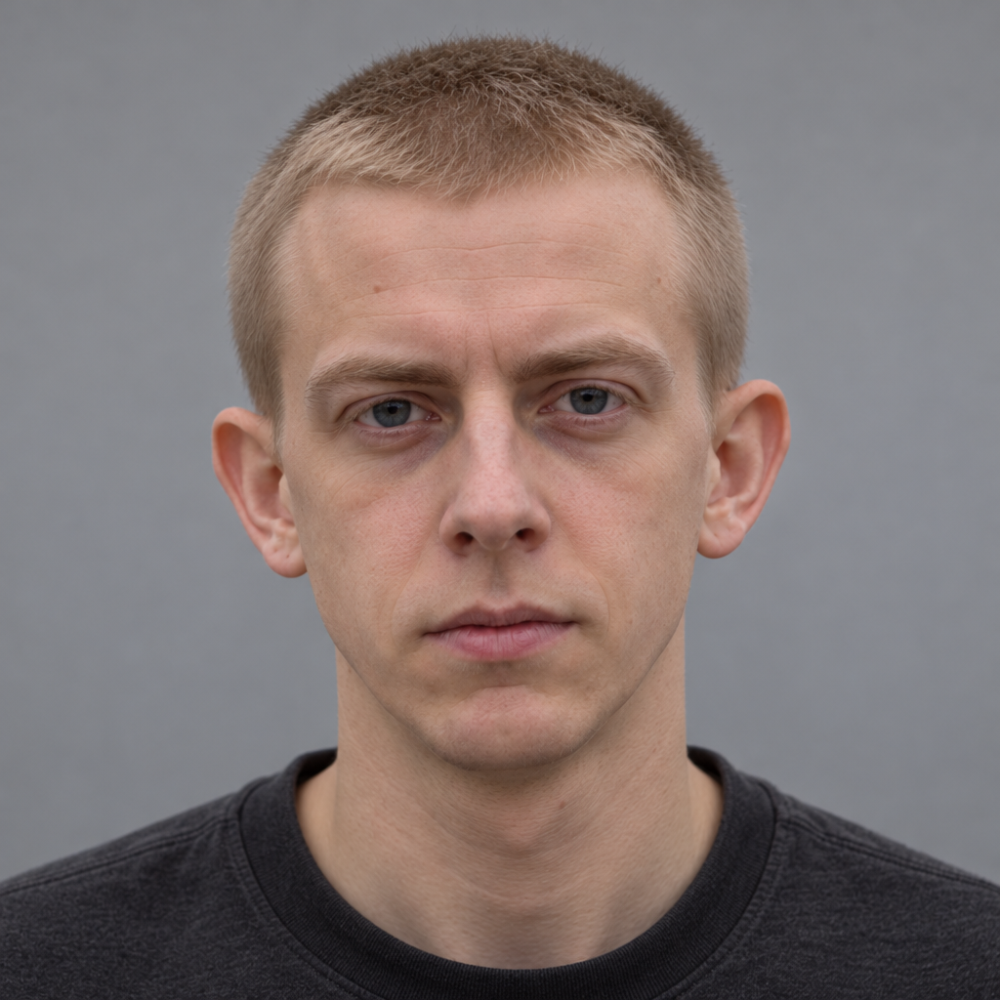

Generate filler 5/6，reference image：D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\6.png


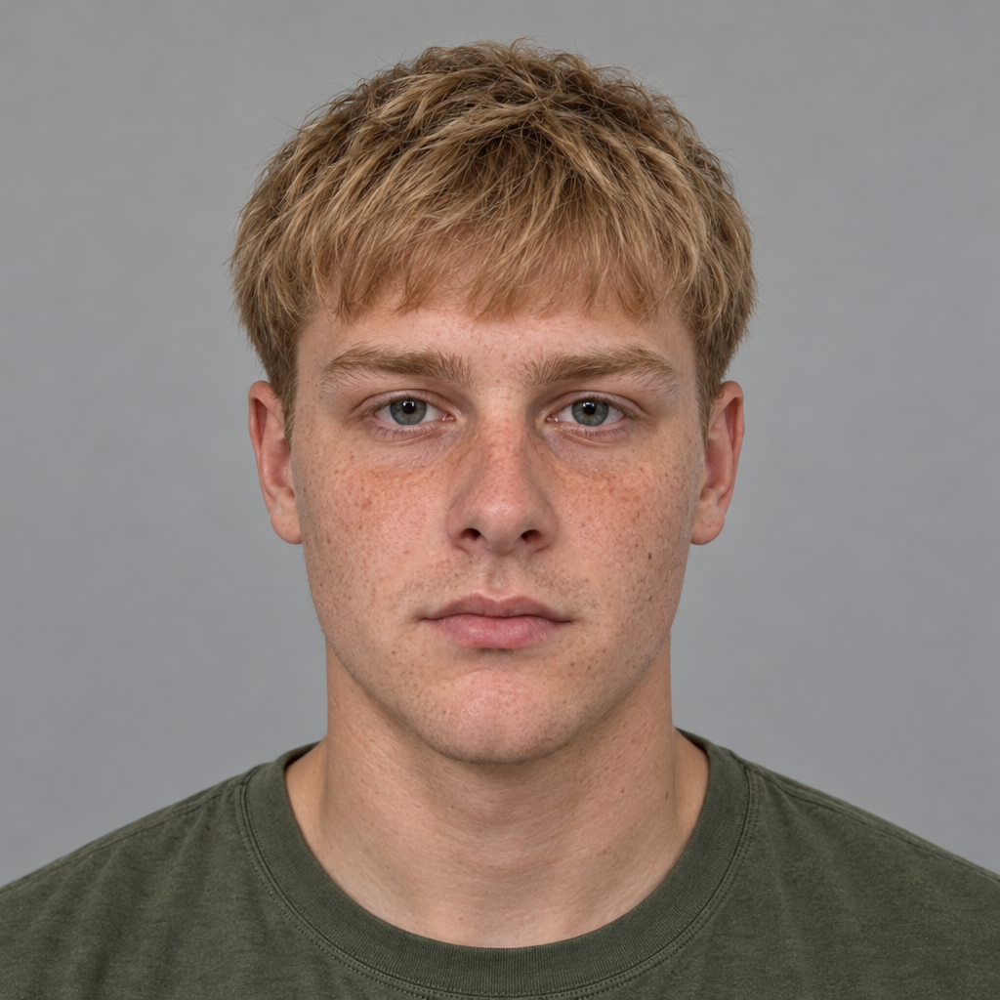

Generate filler 6/6，reference image：D:\PhD\Software\pyWitnessAI\data\UnderAverageFaces\White\5.png


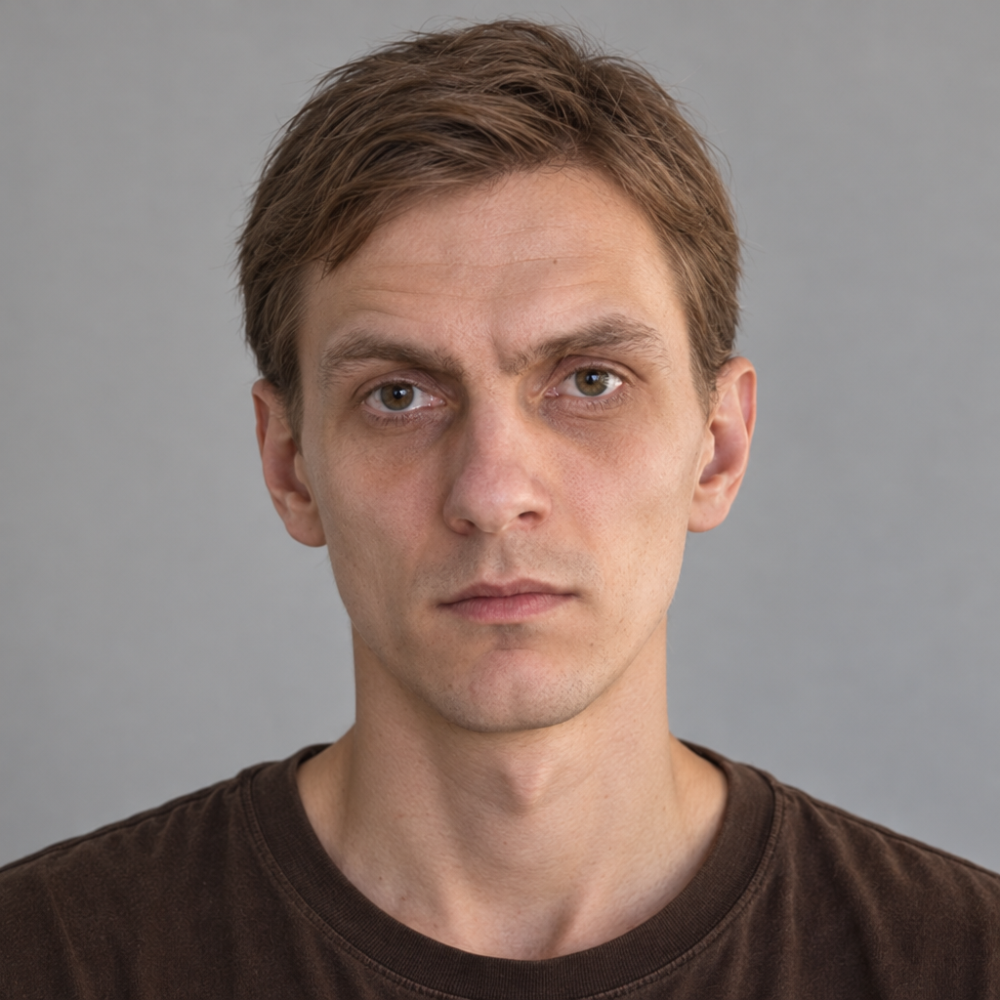

In [13]:
fillers = []
for i, generator in enumerate(generators, 1):
    print(f"Generate filler {i}/6，reference image：{generator.reference_image}", flush=True)
    filler = generator.generate()[0]
    fillers.append(filler)
    display(DisplayImage(filename=filler.path, width=240))

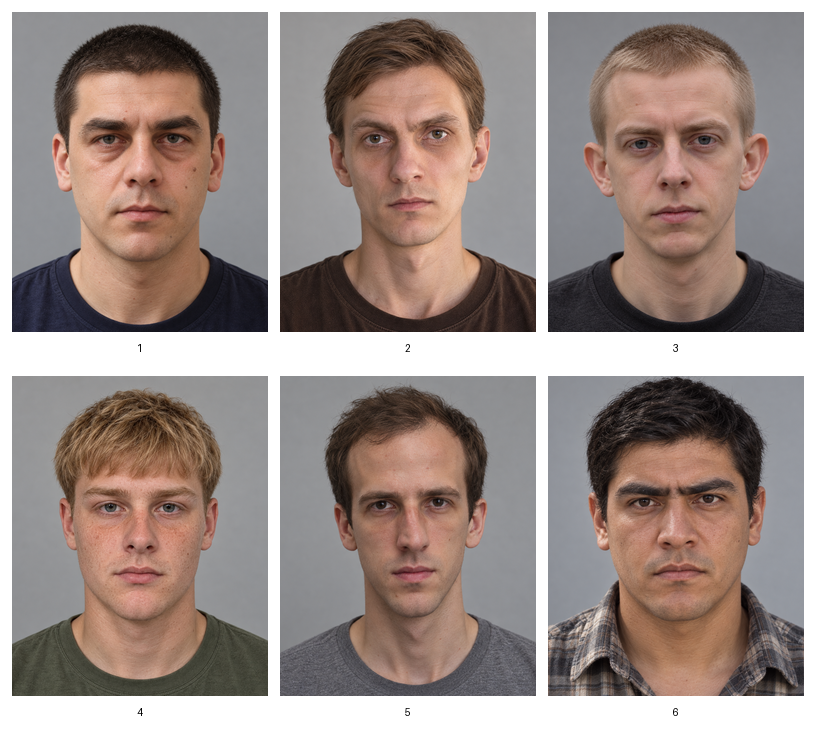

In [14]:
lineup = LineupBuilder(
    suspect=None,
    filler_pool=[filler.path for filler in fillers],
    size=6,
    rows=2,
    target="absent",
    order="random",
    seed=81,
).build()
standardizer = FaceStandardizer()
lineup = lineup.standardize(standardizer)
_ = lineup.show()

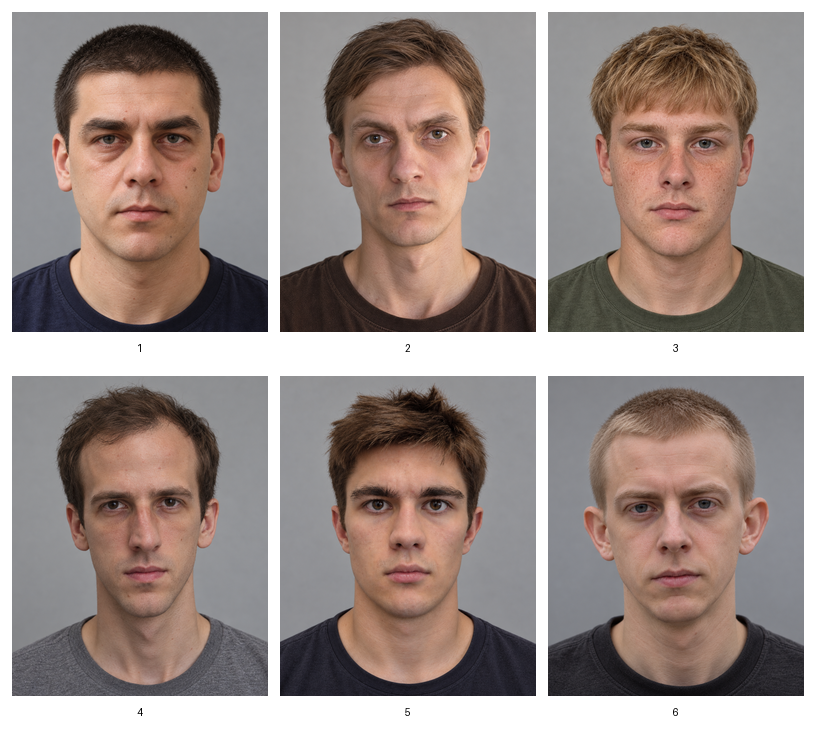

In [18]:
lineup = LineupBuilder(
    suspect="D:/PhD/Studies/FaceGenerate/perp_refer_to_AI_generated_image.png",
    filler_pool=[filler.path for filler in fillers],
    size=6,
    rows=2,
    target="absent",
    order="random",
    seed=81,
).build()
standardizer = FaceStandardizer()
lineup = lineup.standardize(standardizer)
_ = lineup.show()